# Lab 16.2: Activation Patching on GPT-2 Small

Run-only notebook for Chapter 16. Run the cells in order; nothing needs editing. Each section ends with a checkpoint that matches the lab README. The model is GPT-2 small (public weights, downloaded once, about 500 MB) on a laptop CPU.

In [1]:
import os, random, time
import numpy as np, torch, matplotlib
import matplotlib.pyplot as plt
from transformer_lens import HookedTransformer
torch.set_grad_enabled(False)
torch.manual_seed(0)
from importlib.metadata import version
print("torch", torch.__version__, "| transformer-lens", version("transformer-lens"), "| numpy", np.__version__)
t0 = time.time()
model = HookedTransformer.from_pretrained("gpt2", device="cpu")   # GPT-2 small, 124M parameters
print(f"loaded in {time.time() - t0:.0f} s")

torch 2.6.0 | transformer-lens 2.18.0 | numpy 1.26.4


Loaded pretrained model gpt2 into HookedTransformer
loaded in 1 s


## 1. Clean, corrupted and ABC prompts

The clean prompt ends where the indirect object (IO) should come. The corrupted prompt replaces the second mention of the subject (S2) with the IO name, so the answer flips. The ABC prompt replaces S2 with a third name, so neither answer is favored.

In [2]:
NAMES = ["Mary", "John", "Alice", "Bob", "Sarah", "James", "Emma", "David",
         "Laura", "Michael", "Anna", "Daniel", "Maria", "Thomas", "Julia", "Peter"]
PLACES = ["store", "park", "office", "school", "beach", "market", "station", "garden"]
OBJS = ["drink", "ball", "book", "gift", "key", "letter", "ring", "bag"]
TPL = "When {A} and {B} went to the {P}, {B} gave a {O} to"
ROLES = ["BOS", "When", "IO", "and", "S1", "went", "to", "the", "place", ",", "S2", "gave", "a", "object", "END"]

rng = random.Random(0)
clean, corr, io, s = [], [], [], []
for _ in range(48):
    A, B = rng.sample(NAMES, 2); P = rng.choice(PLACES); O = rng.choice(OBJS)
    clean.append(TPL.format(A=A, B=B, P=P, O=O))
    corr.append(TPL.replace("{B} gave", "{A} gave").format(A=A, B=B, P=P, O=O))   # S2 becomes the IO name
    io.append(model.to_single_token(" " + A)); s.append(model.to_single_token(" " + B))
rng2 = random.Random(1)
abc = []
for i in range(48):                       # ABC corruption: same IO and S1, a third name at S2
    A, B = model.to_string(io[i]).strip(), model.to_string(s[i]).strip()
    C = rng2.choice([n for n in NAMES if n not in (A, B)])
    abc.append(clean[i].replace(f", {B} gave", f", {C} gave"))
clean_t, corr_t, abc_t = model.to_tokens(clean), model.to_tokens(corr), model.to_tokens(abc)
io, s = torch.tensor(io), torch.tensor(s)
N, T = clean_t.shape
assert corr_t.shape == clean_t.shape == abc_t.shape, "every prompt must have the same token length"

def logit_diff(logits):
    last = logits[:, -1]
    return last[range(N), io] - last[range(N), s]

clean_logits, clean_cache = model.run_with_cache(clean_t)
corr_logits, corr_cache = model.run_with_cache(corr_t)
abc_logits, abc_cache = model.run_with_cache(abc_t)
LD_clean = logit_diff(clean_logits).mean().item()
LD_corr = logit_diff(corr_logits).mean().item()
LD_abc = logit_diff(abc_logits).mean().item()
print(clean[0]); print(corr[0]); print(abc[0])
print(f"logit difference (IO minus S): clean {LD_clean:.2f}, corrupted {LD_corr:.2f}, ABC {LD_abc:.2f}")
print(f"clean prompts answered correctly: {(logit_diff(clean_logits) > 0).float().mean().item():.0%}")

When Maria and Peter went to the station, Peter gave a drink to
When Maria and Peter went to the station, Maria gave a drink to
When Maria and Peter went to the station, Alice gave a drink to
logit difference (IO minus S): clean 3.74, corrupted -3.88, ABC 0.96
clean prompts answered correctly: 100%


**Checkpoint 1:** clean about 3.74, corrupted about -3.88, all 48 clean prompts correct; ABC close to zero.

## 2. Residual stream patching (denoising)

For each layer and position, copy the clean residual stream into the corrupted run and report the share of the logit difference restored: 0 means as corrupted, 1 means fully clean. This is the slowest cell (180 runs).

72 s


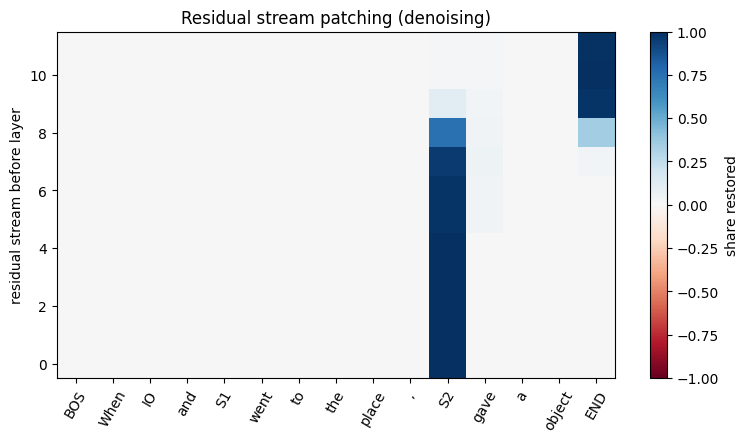

S2 column : [1.   1.   1.   1.   1.   0.98 0.98 0.96 0.75 0.11 0.01 0.02]
END column: [ 0.   -0.   -0.   -0.   -0.   -0.    0.    0.02  0.35  0.98  1.03  0.99]


In [3]:
def restored(ld):            # normalized: 0 = corrupted run, 1 = clean run
    return (ld - LD_corr) / (LD_clean - LD_corr)

t0 = time.time()
resid = np.zeros((12, T))
for layer in range(12):
    name = f"blocks.{layer}.hook_resid_pre"
    for pos in range(T):
        def hook(act, hook, pos=pos):
            act[:, pos] = clean_cache[hook.name][:, pos]
            return act
        out = model.run_with_hooks(corr_t, fwd_hooks=[(name, hook)])
        resid[layer, pos] = restored(logit_diff(out).mean().item())
print(f"{time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(resid, cmap="RdBu", vmin=-1, vmax=1, origin="lower", aspect="auto")
ax.set_xticks(range(T)); ax.set_xticklabels(ROLES, rotation=60)
ax.set_ylabel("residual stream before layer"); fig.colorbar(im, label="share restored")
ax.set_title("Residual stream patching (denoising)"); plt.show()
print("S2 column :", np.round(resid[:, 10], 2))
print("END column:", np.round(resid[:, 14], 2))

**Checkpoint 2:** the S2 column is close to 1 up to layer 7 (0.96), 0.75 before layer 8 and near 0 from layer 9; the END column is near 0 up to layer 7, 0.35 before layer 8 and close to 1 from layer 9.

## 3. Head patching in both directions

Denoising copies one head's clean output into the corrupted run (is it sufficient?). Noising copies its corrupted output into the clean run (is it necessary?). We patch the head at all positions.

132 s
denoising, top heads: 10.7 (-0.50), 5.5 (+0.35), 8.6 (+0.34), 8.10 (+0.31), 9.9 (+0.27), 7.9 (+0.21), 11.10 (-0.21), 3.0 (+0.15), 6.9 (+0.14), 7.3 (+0.12)
noising, top heads:   10.7 (-0.44), 9.9 (+0.23), 5.5 (+0.22), 8.6 (+0.22), 8.10 (+0.22), 11.10 (-0.20), 7.9 (+0.15), 7.3 (+0.11), 10.0 (+0.11), 9.7 (+0.09)


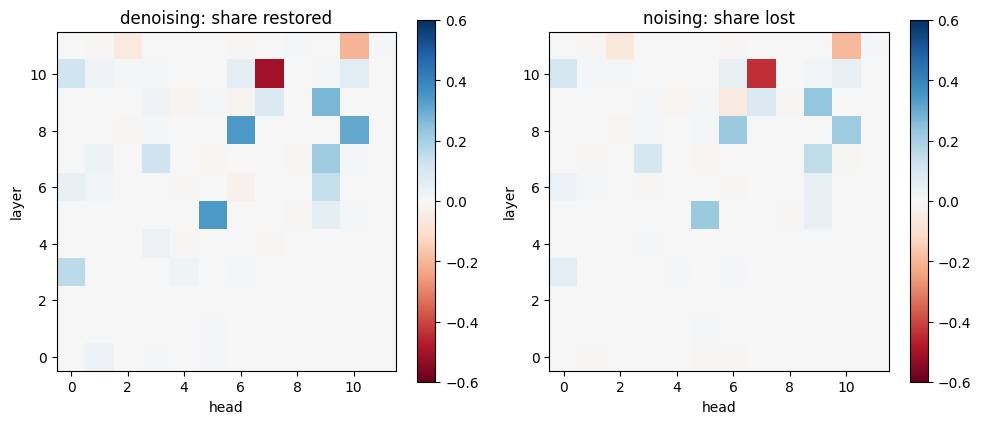

In [4]:
def patch_heads(base_tokens, source_cache, score):
    out = np.zeros((12, 12))
    for layer in range(12):
        name = f"blocks.{layer}.attn.hook_z"
        for h in range(12):
            def hook(act, hook, h=h):
                act[:, :, h] = source_cache[hook.name][:, :, h]
                return act
            ld = logit_diff(model.run_with_hooks(base_tokens, fwd_hooks=[(name, hook)])).mean().item()
            out[layer, h] = score(ld)
    return out

t0 = time.time()
denoise = patch_heads(corr_t, clean_cache, restored)
noise = patch_heads(clean_t, corr_cache, lambda ld: (LD_clean - ld) / (LD_clean - LD_corr))   # share lost
print(f"{time.time() - t0:.0f} s")

def top(M, k=10):
    idx = np.argsort(-np.abs(M).ravel())[:k]
    return ", ".join(f"{i // 12}.{i % 12} ({M.ravel()[i]:+.2f})" for i in idx)
print("denoising, top heads:", top(denoise))
print("noising, top heads:  ", top(noise))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, M, title in zip(axes, [denoise, noise], ["denoising: share restored", "noising: share lost"]):
    im = ax.imshow(M, cmap="RdBu", vmin=-0.6, vmax=0.6, origin="lower")
    ax.set_xlabel("head"); ax.set_ylabel("layer"); ax.set_title(title); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

**Checkpoint 3:** denoising picks out 10.7 (about -0.50), 5.5 and 8.6 (about +0.35), 8.10, 9.9, 7.9, 11.10 (negative), 3.0, 6.9, 7.3 and 10.0. Compare the noising list: which heads appear in both, and which only in one?

## 4. A second corruption: ABC

Repeat head denoising, but take the corrupted run from the ABC prompts. The metric is still IO minus S, normalized between the ABC run and the clean run.

In [5]:
t0 = time.time()
denoise_abc = patch_heads(abc_t, clean_cache, lambda ld: (ld - LD_abc) / (LD_clean - LD_abc))
print(f"{time.time() - t0:.0f} s")
print("ABC denoising, top heads:", top(denoise_abc))
r = np.corrcoef(denoise.ravel(), denoise_abc.ravel())[0, 1]
print(f"correlation of the two head maps: {r:.2f}")

54 s
ABC denoising, top heads: 10.7 (-0.52), 8.10 (+0.45), 9.9 (+0.23), 7.9 (+0.22), 7.3 (+0.21), 8.6 (+0.20), 11.10 (-0.19), 3.0 (+0.19), 5.9 (+0.16), 5.5 (+0.15)
correlation of the two head maps: 0.92


**Checkpoint 4:** the two corruptions agree on many heads but not all; note which heads change rank. A corruption defines the question: S2 swap asks what carries *which name is repeated*; ABC asks what carries *that S1 is repeated at all*.

## 5. Knock out the name movers and look for self-repair

Direct logit attribution (DLA) projects each head's output at the final position onto the difference between the IO and S unembedding vectors (after the final layer-norm scale). We mean-ablate heads 9.9, 9.6 and 10.0 with their average output on ABC prompts and compare DLA before and after.

In [6]:
def dla(cache):
    scale = cache["ln_final.hook_scale"][:, -1]
    direction = model.W_U[:, io] - model.W_U[:, s]
    out = np.zeros((12, 12))
    for layer in range(12):
        z = cache[f"blocks.{layer}.attn.hook_z"][:, -1]
        r = torch.einsum("nhd,hdm->nhm", z, model.W_O[layer]) / scale[:, None, :]
        out[layer] = torch.einsum("nhm,mn->nh", r, direction).mean(0).numpy()
    return out

NAME_MOVERS = [(9, 9), (9, 6), (10, 0)]
def knockout(act, hook):
    layer = int(hook.name.split(".")[1])
    for l, h in NAME_MOVERS:
        if l == layer:
            act[:, :, h] = abc_cache[hook.name][:, :, h].mean(0)
    return act
with model.hooks(fwd_hooks=[(f"blocks.{l}.attn.hook_z", knockout) for l in (9, 10)]):
    ko_logits, ko_cache = model.run_with_cache(clean_t)
before, after = dla(clean_cache), dla(ko_cache)
print(f"logit difference: intact {LD_clean:.2f}, name movers knocked out {logit_diff(ko_logits).mean().item():.2f}")
print("direct contribution of the knocked-out heads before:", round(sum(before[l, h] for l, h in NAME_MOVERS), 2))
change = after - before
for i in np.argsort(-np.abs(change).ravel())[:10]:
    print(f"head {i // 12}.{i % 12}: before {before.ravel()[i]:+.2f}  after {after.ravel()[i]:+.2f}")

logit difference: intact 3.74, name movers knocked out 3.51
direct contribution of the knocked-out heads before: 5.39
head 9.9: before +3.09  after -0.01
head 10.7: before -2.38  after +0.03
head 9.6: before +1.32  after +0.01
head 10.0: before +0.98  after +0.02
head 10.10: before +0.46  after +1.33
head 11.2: before -0.23  after +0.53
head 10.2: before -0.26  after +0.20
head 11.10: before -0.80  after -1.25
head 10.6: before +0.28  after +0.67
head 10.1: before +0.20  after +0.45


**Checkpoint 5:** the logit difference falls only from about 3.74 to about 3.53, although the three heads contributed about 5.4 directly. Heads 10.10, 10.6, 11.2 and 10.1 rise; the negative head 10.7 goes from about -2.4 to about 0.

## Questions

1. In Section 2, why does every early-layer patch at S2 restore the full logit difference? What does that tell you about what early residual patches can and cannot show?
2. Name one head that matters under noising but not under denoising, or the reverse, and give a possible structural reason (see the chapter's Deep box on AND and OR).
3. After the knockout, which two mechanisms recover the logit difference? Why does this make a single-head ablation a poor measure of a head's normal role?

## 6. Save the result tables

The tables of Lab 16.1 (the no-code lab) were written by this cell.

In [7]:
import pandas as pd
os.makedirs("results", exist_ok=True)
heads_idx = [f"layer {l}" for l in range(12)]; heads_col = [f"head {h}" for h in range(12)]
pd.DataFrame(resid.round(3), index=[f"before layer {l}" for l in range(12)], columns=ROLES).to_csv("results/residual_patching.csv")
for name, M in [("head_denoising", denoise), ("head_noising", noise), ("head_denoising_abc", denoise_abc)]:
    pd.DataFrame(M.round(3), index=heads_idx, columns=heads_col).to_csv(f"results/{name}.csv")
rows = [(f"head {l}.{h}", round(before[l, h], 3), round(after[l, h], 3)) for l in range(12) for h in range(12)]
pd.DataFrame(rows, columns=["head", "dla_before", "dla_after_knockout"]).to_csv("results/knockout_dla.csv", index=False)
print(sorted(os.listdir("results")))

['head_denoising.csv', 'head_denoising_abc.csv', 'head_noising.csv', 'knockout_dla.csv', 'residual_patching.csv']
